# Exploración reproducible: `spam_multilingual_augmented`

Este notebook lee el CSV original sin modificarlo. El análisis completo se guarda en [`../reports/spam_multilingual_augmented.md`](../reports/spam_multilingual_augmented.md).

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
while not (HERE / 'notebooks' / 'exploracion-datasets' / 'dataset_audit.py').exists():
    if HERE.parent == HERE:
        raise FileNotFoundError('No se encontró la raíz del repositorio')
    HERE = HERE.parent
sys.path.insert(0, str(HERE / 'notebooks' / 'exploracion-datasets'))
from dataset_audit import DATASETS, analyze_dataset, load_dataset, combined_text
spec = next(item for item in DATASETS if item.slug == 'spam_multilingual_augmented')
df = load_dataset(spec)
result = analyze_dataset(spec)
print(f'Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas')
print(f'Objetivo: {spec.target}')

Dimensiones: 5,572 filas × 23 columnas
Objetivo: labels


## Esquema, tipos y nulos

In [2]:
schema = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'nulos_pct': (df.isna().mean() * 100).round(2),
})
display(schema)

,tipo,nulos,nulos_pct
Unnamed: 0,int64,0,0.00
labels,str,0,0.00
text,str,0,0.00
text_hi,str,0,0.00
text_de,str,0,0.00
text_fr,str,0,0.00
text_es,str,0,0.00
text_zh,str,26,0.47
text_ar,str,1,0.02
text_bn,str,0,0.00


## Clases, duplicados y conflictos

,registros
labels,
ham,4825
spam,747


Filas duplicadas: 0
Filas con texto repetido: 706
Textos con etiquetas conflictivas: 0


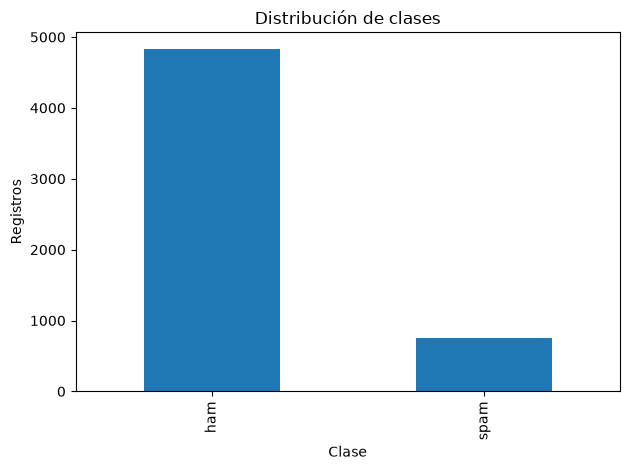

In [3]:
display(df[spec.target].value_counts(dropna=False).rename('registros').to_frame())
print('Filas duplicadas:', result['full_row_duplicates'])
print('Filas con texto repetido:', result['text_duplicates'])
print('Textos con etiquetas conflictivas:', result['conflicting_normalized_texts'])
df[spec.target].astype(str).value_counts().plot(kind='bar', title='Distribución de clases')
plt.xlabel('Clase'); plt.ylabel('Registros'); plt.tight_layout(); plt.show()

## Longitud, idioma y patrones

,caracteres,palabras
count,5572.000000,5572.000000
min,2.000000,0.000000
q25,35.750000,7.000000
median,61.000000,12.000000
mean,80.369167,15.714286
q75,122.000000,23.000000
p95,160.000000,33.000000
max,910.000000,190.000000


Idiomas declarados o estimados: {'en': 2927, 'indeterminado': 2640, 'es': 5}
Filas con URL/correo/teléfono: 108 7 417


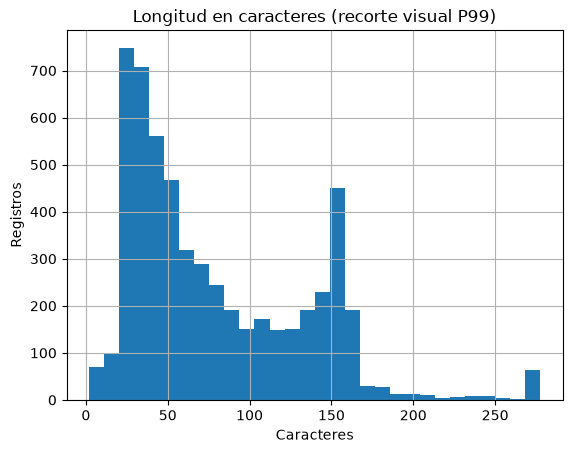

In [4]:
display(pd.DataFrame({
    'caracteres': result['length_characters'],
    'palabras': result['length_words'],
}))
print('Idiomas declarados o estimados:', result['declared_languages'] or result['language_heuristic'])
print('Filas con URL/correo/teléfono:', result['rows_with_url_pattern'], result['rows_with_email_pattern'], result['rows_with_phone_pattern'])
text = combined_text(df, spec.text_columns)
text.str.len().clip(upper=text.str.len().quantile(.99)).hist(bins=30)
plt.title('Longitud en caracteres (recorte visual P99)'); plt.xlabel('Caracteres'); plt.ylabel('Registros'); plt.show()

## Ejemplos sanitizados y conclusión

In [5]:
for label, examples in result['examples'].items():
    print(f'\nClase {label}')
    for example in examples:
        print('-', example)


Clase ham
- I can't right this second, gotta hit people up first
- Can ü all decide faster cos my sis going home liao..

Clase spam
- Spook up your mob with a Halloween collection of a logo & pic message plus a free eerie tone, txt CARD SPOOK to 8007 zed 08701417012150p per logo/pic
- complimentary 4 STAR Ibiza Holiday or £10,000 cash needs your URGENT collection. [telefono-oculto] NOW from Landline not to lose out! Box434SK38WP150PPM18+


La interpretación, riesgos de fuga, sesgos, utilidad para Random Forest y estrategia de combinación están documentados en [`../reports/spam_multilingual_augmented.md`](../reports/spam_multilingual_augmented.md).